# Lab 04 


In [3]:
import re
import time
import nltk
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, SnowballStemmer

stop_words = set(stopwords.words("english"))
porter = PorterStemmer()
snowball = SnowballStemmer("english")

# `Task 01: Lowercasing Basics and Its Drawbacks`

In [4]:
corpus = [
    "Apple released a new phone today.",
    "I ate an apple after lunch.",
    "APPLE shares increased this week.",
    "The US announced a new policy.",
    "Please send us the final report.",
    "Amazon sells many products online.",
    "The amazon rainforest is very large.",
    "May is a month of the year.",
    "You may leave after the class.",
    "Python is popular for NLP work."
]

def words_from_text(text):
    return re.findall(r"\b[A-Za-z]+\b", text)

original_words = []
lowercase_words = []

for sentence in corpus:
    original_words.extend(words_from_text(sentence))
    lowercase_words.extend(words_from_text(sentence.lower()))

original_vocab = set(original_words)
lowercase_vocab = set(lowercase_words)

print("Original vocabulary size:", len(original_vocab))
print("Lowercased vocabulary size:", len(lowercase_vocab))
print("Vocabulary reduction:", len(original_vocab) - len(lowercase_vocab))

Original vocabulary size: 50
Lowercased vocabulary size: 44
Vocabulary reduction: 6


In [5]:
lowercased_corpus = [sentence.lower() for sentence in corpus]

comparison = pd.DataFrame({
    "Original": corpus,
    "Lowercased": lowercased_corpus
})

comparison

,Original,Lowercased
0,Apple released a new phone today.,apple released a new phone today.
1,I ate an apple after lunch.,i ate an apple after lunch.
2,APPLE shares increased this week.,apple shares increased this week.
3,The US announced a new policy.,the us announced a new policy.
4,Please send us the final report.,please send us the final report.
5,Amazon sells many products online.,amazon sells many products online.
6,The amazon rainforest is very large.,the amazon rainforest is very large.
7,May is a month of the year.,may is a month of the year.
8,You may leave after the class.,you may leave after the class.
9,Python is popular for NLP work.,python is popular for nlp work.


In [6]:
ambiguity_examples = pd.DataFrame({
    "Original forms": [
        "US and us",
        "Apple and apple",
        "May and may"
    ],
    "Different meanings before lowercasing": [
        "US means the United States, while us is a pronoun.",
        "Apple can mean the company, while apple can mean the fruit.",
        "May can mean the month, while may can express possibility."
    ],
    "After lowercasing": [
        "Both become us.",
        "Both become apple.",
        "Both become may."
    ]
})

ambiguity_examples

,Original forms,Different meanings before lowercasing,After lowercasing
0,US and us,"US means the United States, while us is a pron...",Both become us.
1,Apple and apple,"Apple can mean the company, while apple can me...",Both become apple.
2,May and may,"May can mean the month, while may can express ...",Both become may.


In [7]:
print(
    "Lowercasing reduces the number of different word forms, which can make text processing simpler. "
    "However, it can also remove useful information. In Named Entity Recognition, capitalization can help "
    "identify names such as Apple, US, or May. In sentiment analysis, unusual capitalization such as GREAT "
    "or TERRIBLE may show emphasis. In search, lowercasing can mix words that look the same after case "
    "normalization but originally had different meanings. Therefore, lowercasing should be used according "
    "to the NLP task instead of being applied blindly."
)

Lowercasing reduces the number of different word forms, which can make text processing simpler. However, it can also remove useful information. In Named Entity Recognition, capitalization can help identify names such as Apple, US, or May. In sentiment analysis, unusual capitalization such as GREAT or TERRIBLE may show emphasis. In search, lowercasing can mix words that look the same after case normalization but originally had different meanings. Therefore, lowercasing should be used according to the NLP task instead of being applied blindly.


# `Task 02: Noise Removal Pipeline`

In [8]:
noisy_texts = [
    "Amazing service!!! Visit https://example.com now 😍",
    "<p>This product is GREAT</p>   I love it!",
    "@ali Thanks for the help!!! #Helpful 😊",
    "Check this out: http://shop.com/item?id=4 #Sale",
    "Worst delivery ever 😡   @store please reply",
    "<b>Excellent</b> quality and fast shipping!!!",
    "I paid $100 for this C++ course. #Programming",
    "New update available at https://app.com/update 🚀",
    "@support My order is late... #NotHappy",
    "<div>Good value</div> for money 👍",
    "Follow @brand for more deals!!! #Shopping",
    "This   phone   is   very   fast 😃",
    "Read more at www.example.org/news #Technology",
    "<span>Battery life is poor</span> 😞",
    "@john I cannot open the file!!! https://files.com/test #Help"
]

noisy_texts[:5]

['Amazing service!!! Visit https://example.com now 😍',
 '<p>This product is GREAT</p>   I love it!',
 '@ali Thanks for the help!!! #Helpful 😊',
 'Check this out: http://shop.com/item?id=4 #Sale',
 'Worst delivery ever 😡   @store please reply']

In [9]:
def remove_urls(text):
    text = re.sub(r"https?://\S+", "", text)
    text = re.sub(r"www\.\S+", "", text)
    return text

def remove_html(text):
    return re.sub(r"<.*?>", "", text)

def handle_mentions_hashtags(text):
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    return text

def remove_punctuation(text):
    return re.sub(r"[^\w\s]", "", text)

def remove_extra_spaces(text):
    return re.sub(r"\s+", " ", text).strip()

In [10]:
def clean_text(text):
    text = remove_urls(text)
    text = remove_html(text)
    text = handle_mentions_hashtags(text)
    text = remove_punctuation(text)
    text = remove_extra_spaces(text)
    return text

cleaned_texts = [clean_text(text) for text in noisy_texts]

clean_table = pd.DataFrame({
    "Before": noisy_texts[:5],
    "After": cleaned_texts[:5]
})

clean_table

,Before,After
0,Amazing service!!! Visit https://example.com n...,Amazing service Visit now
1,<p>This product is GREAT</p> I love it!,This product is GREAT I love it
2,@ali Thanks for the help!!! #Helpful 😊,Thanks for the help Helpful
3,Check this out: http://shop.com/item?id=4 #Sale,Check this out Sale
4,Worst delivery ever 😡 @store please reply,Worst delivery ever please reply


In [11]:
def clean_text_different_order(text):
    text = remove_punctuation(text)
    text = remove_urls(text)
    text = remove_html(text)
    text = handle_mentions_hashtags(text)
    text = remove_extra_spaces(text)
    return text

order_example = "@ali Read this https://example.com #Important"

print("Original:", order_example)
print("Normal order:", clean_text(order_example))
print("Different order:", clean_text_different_order(order_example))
print()
print(
    "The order changes the result. If punctuation is removed first, the @ sign disappears before the mention "
    "function runs, so the username may remain. The URL can also be damaged before the URL-removal function "
    "gets a chance to recognize it."
)

Original: @ali Read this https://example.com #Important
Normal order: Read this Important
Different order: ali Read this httpsexamplecom Important

The order changes the result. If punctuation is removed first, the @ sign disappears before the mention function runs, so the username may remain. The URL can also be damaged before the URL-removal function gets a chance to recognize it.


In [12]:
over_cleaning_examples = [
    "I use C++ for programming.",
    "The price is $100.",
    "Email me at student@mail.com."
]

for text in over_cleaning_examples:
    print("Before:", text)
    print("After: ", clean_text(text))
    print()

print(
    "The cleaning goes too far in these examples because punctuation carries meaning. C++ loses its plus signs, "
    "$100 loses the currency symbol, and an email address is damaged. A real pipeline should preserve symbols "
    "that are important for the task."
)

Before: I use C++ for programming.
After:  I use C for programming

Before: The price is $100.
After:  The price is 100

Before: Email me at student@mail.com.
After:  Email me at studentcom

The cleaning goes too far in these examples because punctuation carries meaning. C++ loses its plus signs, $100 loses the currency symbol, and an email address is damaged. A real pipeline should preserve symbols that are important for the task.


# `Task 03: Stop-Word Removal and Its Effect on Vocabulary`

In [13]:
stop_word_list = stopwords.words("english")

print("First 20 stop-words:")
print(stop_word_list[:20])
print()
print("Total number of stop-words:", len(stop_word_list))

First 20 stop-words:
['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been']

Total number of stop-words: 198


In [14]:
movie_reviews_data = [
    "The movie was very interesting and the acting was excellent.",
    "I really liked the story and the characters in this film.",
    "The film was slow but the ending was very good.",
    "This movie has a strong story and a talented cast.",
    "The director made the scenes easy to understand and enjoyable.",
    "The movie was boring and the story was too long.",
    "I did not enjoy the film because the acting was weak.",
    "The plot was simple but the characters were believable.",
    "This was a funny movie and the audience enjoyed it.",
    "The film had good music but some scenes were unnecessary.",
    "The actor gave a strong performance in the final scene.",
    "The movie was not perfect but it was still entertaining.",
    "The story was confusing and the ending did not make sense.",
    "The director created a beautiful film with strong characters.",
    "The movie had many problems but the acting saved it.",
    "I watched the film with my family and we all liked it.",
    "The first half was slow and the second half was exciting.",
    "The characters were interesting and the story felt realistic.",
    "This movie was too long and I lost interest near the end.",
    "The film was simple, clear, and enjoyable to watch."
]

def tokenize(text):
    return re.findall(r"\b[a-zA-Z]+\b", text.lower())

before_tokens = []
after_tokens = []

for review in movie_reviews_data:
    tokens = tokenize(review)
    before_tokens.extend(tokens)
    after_tokens.extend([word for word in tokens if word not in stop_words])

before_vocab = set(before_tokens)
after_vocab = set(after_tokens)

before_average = len(before_tokens) / len(movie_reviews_data)
after_average = len(after_tokens) / len(movie_reviews_data)

stats = pd.DataFrame({
    "Measure": ["Token count", "Vocabulary size", "Average sentence length"],
    "Before": [len(before_tokens), len(before_vocab), round(before_average, 2)],
    "After": [len(after_tokens), len(after_vocab), round(after_average, 2)]
})

stats

,Measure,Before,After
0,Token count,204.0,97.00
1,Vocabulary size,86.0,63.00
2,Average sentence length,10.2,4.85


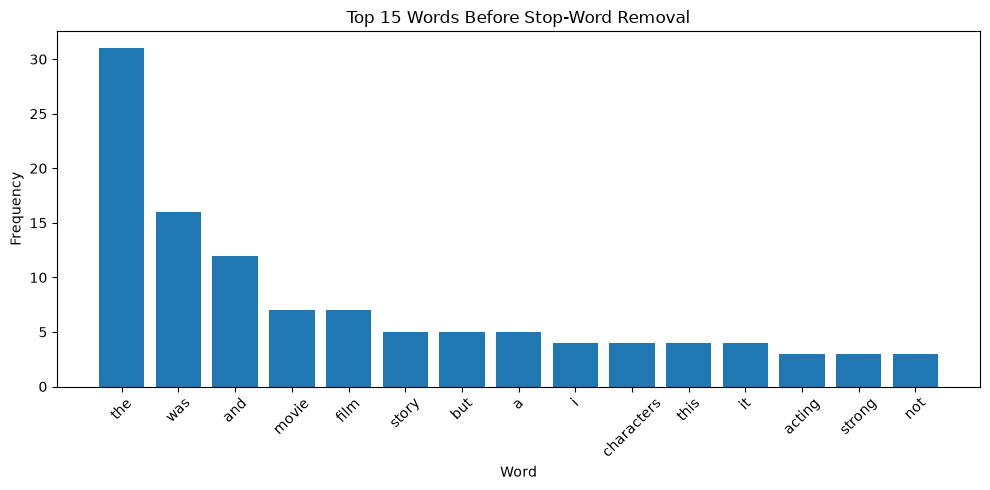

In [15]:
before_counts = Counter(before_tokens)
top_before = before_counts.most_common(15)

words_before = [item[0] for item in top_before]
counts_before = [item[1] for item in top_before]

plt.figure(figsize=(10, 5))
plt.bar(words_before, counts_before)
plt.title("Top 15 Words Before Stop-Word Removal")
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

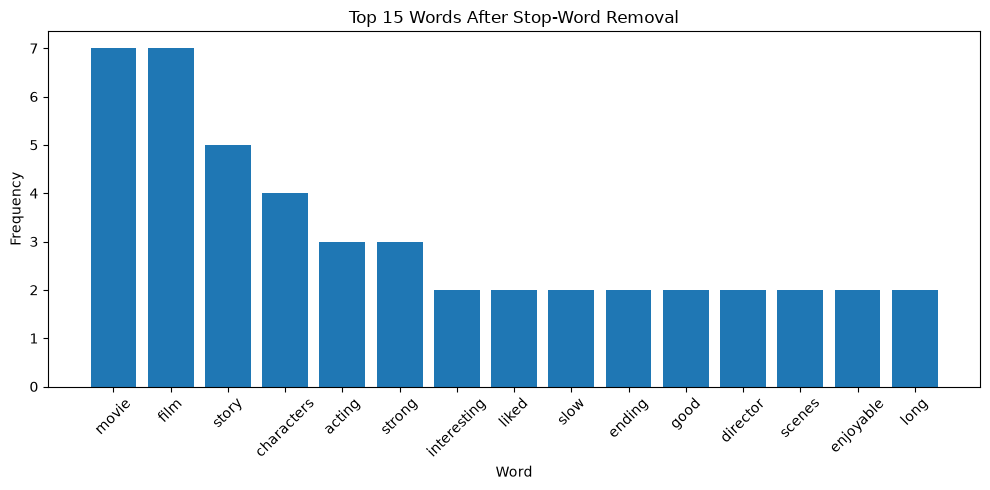

In [16]:
after_counts = Counter(after_tokens)
top_after = after_counts.most_common(15)

words_after = [item[0] for item in top_after]
counts_after = [item[1] for item in top_after]

plt.figure(figsize=(10, 5))
plt.bar(words_after, counts_after)
plt.title("Top 15 Words After Stop-Word Removal")
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [17]:
custom_words = {
    "movie": "It appears often in movie reviews and usually does not show opinion by itself.",
    "film": "It is another common name for the item being reviewed.",
    "actor": "It is a common domain word and may appear in many reviews.",
    "acting": "It is frequent in this domain and may dominate word counts.",
    "story": "It is a common review topic rather than a general sentiment word.",
    "scene": "It is a frequent movie-related term.",
    "scenes": "It is the plural form of a common movie-related term.",
    "character": "It is common in reviews and can be removed for some topic-level analysis.",
    "characters": "It is another frequent form of the same domain concept.",
    "director": "It is a common movie-domain word that may not be useful for some tasks."
}

custom_stop_words = stop_words.union(custom_words.keys())

custom_table = pd.DataFrame({
    "Domain-specific stop-word": list(custom_words.keys()),
    "Reason": list(custom_words.values())
})

custom_table

,Domain-specific stop-word,Reason
0,movie,It appears often in movie reviews and usually ...
1,film,It is another common name for the item being r...
2,actor,It is a common domain word and may appear in m...
3,acting,It is frequent in this domain and may dominate...
4,story,It is a common review topic rather than a gene...
5,scene,It is a frequent movie-related term.
6,scenes,It is the plural form of a common movie-relate...
7,character,It is common in reviews and can be removed for...
8,characters,It is another frequent form of the same domain...
9,director,It is a common movie-domain word that may not ...


# `Task 04: Risks of Stop-Word Removal (Sentiment, MT, Chatbots)`

In [18]:
from nltk.sentiment import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()

negation_sentences = [
    "This movie is not good.",
    "I am never happy with this service.",
    "There is no problem with my order.",
    "The product is not bad.",
    "I do not hate this app."
]

def remove_stop_words(text):
    tokens = tokenize(text)
    return " ".join([word for word in tokens if word not in stop_words])

def sentiment_label(text):
    score = sia.polarity_scores(text)["compound"]
    if score > 0.05:
        return "Positive"
    if score < -0.05:
        return "Negative"
    return "Neutral"

sentiment_rows = []

for sentence in negation_sentences:
    reduced = remove_stop_words(sentence)
    original_sentiment = sentiment_label(sentence)
    reduced_sentiment = sentiment_label(reduced)
    sentiment_rows.append([
        sentence,
        reduced,
        original_sentiment,
        reduced_sentiment,
        original_sentiment != reduced_sentiment
    ])

sentiment_table = pd.DataFrame(
    sentiment_rows,
    columns=["Original", "After stop-word removal", "Original sentiment", "New sentiment", "Changed"]
)

sentiment_table

,Original,After stop-word removal,Original sentiment,New sentiment,Changed
0,This movie is not good.,movie good,Negative,Positive,True
1,I am never happy with this service.,never happy service,Negative,Negative,False
2,There is no problem with my order.,problem order,Negative,Negative,False
3,The product is not bad.,product bad,Positive,Negative,True
4,I do not hate this app.,hate app,Positive,Negative,True


In [64]:
translation_sentences = [
    "I do not want to cancel my order.",
    "She is not happy with the service.",
    "There is no problem with this product."
]

original_urdu = [
    "میں اپنا آرڈر منسوخ نہیں کرنا چاہتا۔",
    "وہ سروس سے خوش نہیں ہے۔",
    "اس پروڈکٹ میں کوئی مسئلہ نہیں ہے۔"
]

reduced_urdu = [
    "آرڈر منسوخ کرنا چاہتا ہوں۔",
    "سروس سے خوش۔",
    "پروڈکٹ کا مسئلہ۔"
]

translation_rows = []

for i in range(len(translation_sentences)):
    sentence = translation_sentences[i]
    reduced = remove_stop_words(sentence)

    translation_rows.append([
        sentence,
        reduced,
        original_urdu[i],
        reduced_urdu[i]
    ])

translation_table = pd.DataFrame(
    translation_rows,
    columns=[
        "Original English",
        "Reduced English",
        "Original Urdu",
        "Reduced Urdu"
    ]
)

translation_table

,Original English,Reduced English,Original Urdu,Reduced Urdu
0,I do not want to cancel my order.,want cancel order,میں اپنا آرڈر منسوخ نہیں کرنا چاہتا۔,آرڈر منسوخ کرنا چاہتا ہوں۔
1,She is not happy with the service.,happy service,وہ سروس سے خوش نہیں ہے۔,سروس سے خوش۔
2,There is no problem with this product.,problem product,اس پروڈکٹ میں کوئی مسئلہ نہیں ہے۔,پروڈکٹ کا مسئلہ۔


In [21]:
print(
    "The reduced sentences can lose words such as not, no, pronouns, and helping verbs. These words are important "
    "for grammar and meaning in translation. As a result, the Urdu translation of the reduced text can express a "
    "different or incomplete message."
)

The reduced sentences can lose words such as not, no, pronouns, and helping verbs. These words are important for grammar and meaning in translation. As a result, the Urdu translation of the reduced text can express a different or incomplete message.


In [22]:
chatbot_queries = [
    "How can I not be charged again?",
    "Why was my payment not accepted?",
    "Can I cancel my order before it ships?",
    "I do not want automatic renewal.",
    "What is the status of my order?"
]

chatbot_issues = [
    "Removing not can change the request into the opposite meaning.",
    "Removing not can hide the actual payment problem.",
    "Removing small connecting words can make the timing of cancellation less clear.",
    "Removing not can make the system think the user wants automatic renewal.",
    "The reduced query may still be understandable, but important grammatical context is lost."
]

chatbot_rows = []

for query, issue in zip(chatbot_queries, chatbot_issues):
    chatbot_rows.append([query, remove_stop_words(query), issue])

chatbot_table = pd.DataFrame(
    chatbot_rows,
    columns=["Original query", "After stop-word removal", "Possible damage"]
)

chatbot_table

,Original query,After stop-word removal,Possible damage
0,How can I not be charged again?,charged,Removing not can change the request into the o...
1,Why was my payment not accepted?,payment accepted,Removing not can hide the actual payment problem.
2,Can I cancel my order before it ships?,cancel order ships,Removing small connecting words can make the t...
3,I do not want automatic renewal.,want automatic renewal,Removing not can make the system think the use...
4,What is the status of my order?,status order,"The reduced query may still be understandable,..."


In [23]:
important_negations = {"no", "not", "nor", "never"}

safe_stop_words = stop_words - important_negations

def safe_remove_stop_words(text):
    tokens = tokenize(text)
    return " ".join([word for word in tokens if word not in safe_stop_words])

safe_rows = []

for sentence in negation_sentences:
    reduced = safe_remove_stop_words(sentence)
    original_sentiment = sentiment_label(sentence)
    safe_sentiment = sentiment_label(reduced)
    safe_rows.append([
        sentence,
        reduced,
        original_sentiment,
        safe_sentiment,
        original_sentiment != safe_sentiment
    ])

safe_table = pd.DataFrame(
    safe_rows,
    columns=["Original", "Safe cleaning", "Original sentiment", "New sentiment", "Changed"]
)

safe_table

,Original,Safe cleaning,Original sentiment,New sentiment,Changed
0,This movie is not good.,movie not good,Negative,Negative,False
1,I am never happy with this service.,never happy service,Negative,Negative,False
2,There is no problem with my order.,no problem order,Negative,Negative,False
3,The product is not bad.,product not bad,Positive,Positive,False
4,I do not hate this app.,not hate app,Positive,Positive,False


In [24]:
print(
    "A safer strategy is to keep negation words such as no, not, nor, and never. Stop-word removal should also be "
    "adjusted for the task. This reduces the chance of reversing sentiment or damaging the user's intent."
)

A safer strategy is to keep negation words such as no, not, nor, and never. Stop-word removal should also be adjusted for the task. This reduces the chance of reversing sentiment or damaging the user's intent.


# `Task 05: Hands-On with the Porter Stemmer`

In [25]:
stemming_words = [
    "running", "runs", "runner", "studies", "studied", "studying",
    "happily", "happiness", "generalization", "generalized",
    "better", "best", "was", "were", "children", "mice",
    "cars", "boxes", "walking", "walked", "easily", "fairness",
    "connection", "connected", "relational", "relation",
    "universities", "universe", "organization", "organ",
    "generous", "general", "supply", "supplier", "analysis",
    "analyze", "creation", "create"
]

expected_roots = {
    "running": "run",
    "runs": "run",
    "runner": "runner",
    "studies": "study",
    "studied": "study",
    "studying": "study",
    "happily": "happy",
    "happiness": "happy",
    "generalization": "general",
    "generalized": "general",
    "better": "good",
    "best": "good",
    "was": "be",
    "were": "be",
    "children": "child",
    "mice": "mouse",
    "cars": "car",
    "boxes": "box",
    "walking": "walk",
    "walked": "walk",
    "easily": "easy",
    "fairness": "fair",
    "connection": "connect",
    "connected": "connect",
    "relational": "relate",
    "relation": "relate",
    "universities": "university",
    "universe": "universe",
    "organization": "organize",
    "organ": "organ",
    "generous": "generous",
    "general": "general",
    "supply": "supply",
    "supplier": "supply",
    "analysis": "analyze",
    "analyze": "analyze",
    "creation": "create",
    "create": "create"
}

stemming_rows = []

for word in stemming_words:
    stem = porter.stem(word)
    expected = expected_roots[word]
    status = "Correct" if stem == expected else "Incorrect"
    stemming_rows.append([word, stem, status])

stemming_table = pd.DataFrame(
    stemming_rows,
    columns=["Word", "Stem", "Correct/Incorrect"]
)

stemming_table

,Word,Stem,Correct/Incorrect
0,running,run,Correct
1,runs,run,Correct
2,runner,runner,Correct
3,studies,studi,Incorrect
4,studied,studi,Incorrect
5,studying,studi,Incorrect
6,happily,happili,Incorrect
7,happiness,happi,Incorrect
8,generalization,gener,Incorrect
9,generalized,gener,Incorrect


In [26]:
over_stemming_pairs = [
    ("universe", "university"),
    ("general", "generous"),
    ("organization", "organ")
]

over_rows = []

for first, second in over_stemming_pairs:
    over_rows.append([
        first,
        porter.stem(first),
        second,
        porter.stem(second)
    ])

over_table = pd.DataFrame(
    over_rows,
    columns=["Word 1", "Stem 1", "Word 2", "Stem 2"]
)

over_table

,Word 1,Stem 1,Word 2,Stem 2
0,universe,univers,university,univers
1,general,gener,generous,gener
2,organization,organ,organ,organ


In [27]:
print(
    "These are over-stemming examples because words with different meanings are reduced to the same stem. "
    "The stemmer removes too much information and makes the words look related even when their meanings are different."
)

These are over-stemming examples because words with different meanings are reduced to the same stem. The stemmer removes too much information and makes the words look related even when their meanings are different.


In [28]:
under_stemming_pairs = [
    ("analysis", "analyze"),
    ("create", "creation"),
    ("supply", "supplier")
]

under_rows = []

for first, second in under_stemming_pairs:
    under_rows.append([
        first,
        porter.stem(first),
        second,
        porter.stem(second)
    ])

under_table = pd.DataFrame(
    under_rows,
    columns=["Related word 1", "Stem 1", "Related word 2", "Stem 2"]
)

under_table

,Related word 1,Stem 1,Related word 2,Stem 2
0,analysis,analysi,analyze,analyz
1,create,creat,creation,creation
2,supply,suppli,supplier,supplier


In [29]:
print(
    "These are under-stemming examples because related words are left with different stems. "
    "The stemmer does not reduce them far enough to the same useful root."
)

These are under-stemming examples because related words are left with different stems. The stemmer does not reduce them far enough to the same useful root.


In [30]:
stemmer_comparison = []

for word in stemming_words:
    porter_stem = porter.stem(word)
    snowball_stem = snowball.stem(word)
    if porter_stem != snowball_stem:
        stemmer_comparison.append([word, porter_stem, snowball_stem])

stemmer_comparison_table = pd.DataFrame(
    stemmer_comparison,
    columns=["Word", "Porter", "Snowball"]
)

stemmer_comparison_table

,Word,Porter,Snowball
0,generalization,gener,general
1,generalized,gener,general
2,was,wa,was
3,generous,gener,generous
4,general,gener,general


# `Task 06: Lemmatization (spaCy) vs. Stemming`

In [31]:
import spacy

try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    from spacy.cli import download
    download("en_core_web_sm")
    nlp = spacy.load("en_core_web_sm")

In [32]:
paragraph = (
    "Natural language processing helps computers work with human language. Students often begin by cleaning text, "
    "splitting sentences into words, and studying how those words are used. A simple stemmer removes endings from "
    "words, but it does not always produce a real dictionary word. Lemmatization uses more grammatical information. "
    "For example, better can become good, children can become child, and was can become be. Yesterday the students "
    "went to the laboratory and wrote several short programs. They were testing how machines understand sentences. "
    "Some programs worked quickly, while others were slower because they performed deeper linguistic analysis. "
    "The teacher explained that words can have different meanings depending on their part of speech. The students "
    "also studied mice and other examples where the correct base form cannot be found by simply cutting letters "
    "from the end. This comparison helped them understand why stemming is fast and simple while lemmatization is "
    "usually more accurate and linguistically meaningful."
)

doc = nlp(paragraph)

lemma_rows = []

for token in doc:
    if token.is_alpha:
        lemma_rows.append([token.text, token.lemma_, token.pos_])

lemma_table = pd.DataFrame(
    lemma_rows,
    columns=["Token", "Lemma", "POS"]
)

print("Number of words:", len(lemma_table))
lemma_table

Number of words: 155


,Token,Lemma,POS
0,Natural,natural,ADJ
1,language,language,NOUN
2,processing,processing,NOUN
3,helps,help,VERB
4,computers,computer,NOUN
...,...,...,...
150,more,more,ADV
151,accurate,accurate,ADJ
152,and,and,CCONJ
153,linguistically,linguistically,ADV


In [33]:
comparison_rows = []

for token in doc:
    if token.is_alpha:
        comparison_rows.append([
            token.text,
            token.pos_,
            porter.stem(token.text.lower()),
            token.lemma_.lower()
        ])

lemma_stem_table = pd.DataFrame(
    comparison_rows,
    columns=["Token", "POS", "Stem", "Lemma"]
)

lemma_stem_table

,Token,POS,Stem,Lemma
0,Natural,ADJ,natur,natural
1,language,NOUN,languag,language
2,processing,NOUN,process,processing
3,helps,VERB,help,help
4,computers,NOUN,comput,computer
...,...,...,...,...
150,more,ADV,more,more
151,accurate,ADJ,accur,accurate
152,and,CCONJ,and,and
153,linguistically,ADV,linguist,linguistically


In [34]:
better_examples = lemma_stem_table[
    lemma_stem_table["Token"].str.lower().isin(
        ["better", "was", "were", "children", "went", "mice"]
    )
]

better_examples

,Token,POS,Stem,Lemma
50,better,ADV,better,well
54,children,NOUN,children,child
59,was,AUX,wa,be
66,went,VERB,went,go
76,were,AUX,were,be
88,were,AUX,were,be
115,mice,NOUN,mice,mouse


In [35]:
print(
    "Lemmatization performs better on these examples because it uses linguistic information such as the POS tag. "
    "For example, was and were are recognized as forms of the verb be, and better can be linked to good. "
    "A stemmer mainly removes letters by rules, so it cannot reliably make these grammatical connections."
)

Lemmatization performs better on these examples because it uses linguistic information such as the POS tag. For example, was and were are recognized as forms of the verb be, and better can be linked to good. A stemmer mainly removes letters by rules, so it cannot reliably make these grammatical connections.


In [36]:
words_for_speed = [token.text.lower() for token in doc if token.is_alpha]

start = time.time()

for _ in range(100):
    stemmed_words = [porter.stem(word) for word in words_for_speed]

stemming_time = time.time() - start

start = time.time()

for _ in range(100):
    lemmatized_doc = nlp(paragraph)

lemmatization_time = time.time() - start

print("Stemming time:", round(stemming_time, 4), "seconds")
print("Lemmatization time:", round(lemmatization_time, 4), "seconds")

Stemming time: 0.1867 seconds
Lemmatization time: 3.4497 seconds


In [37]:
print(
    "Stemming is useful when speed and simple word reduction are more important than perfect linguistic forms, "
    "such as quick search indexing. Lemmatization is better when correct base words and grammatical meaning are "
    "important, such as information extraction, chatbots, and detailed text analysis."
)

Stemming is useful when speed and simple word reduction are more important than perfect linguistic forms, such as quick search indexing. Lemmatization is better when correct base words and grammatical meaning are important, such as information extraction, chatbots, and detailed text analysis.


# `Task 07: Preprocessing Pipeline`

In [41]:
from nltk.corpus import movie_reviews
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

In [42]:
def preprocess_text(text, lowercase=True, noise_removal=True, remove_stopwords=False, method=None):
    if lowercase:
        text = text.lower()

    if noise_removal:
        text = remove_urls(text)
        text = remove_html(text)
        text = handle_mentions_hashtags(text)
        text = remove_extra_spaces(text)

    tokens = re.findall(r"\b[a-zA-Z]+\b", text)

    if remove_stopwords:
        tokens = [word for word in tokens if word not in stop_words]

    if method == "stemming":
        tokens = [porter.stem(word) for word in tokens]

    if method == "lemmatization":
        doc = nlp(" ".join(tokens))
        tokens = [token.lemma_.lower() for token in doc if token.is_alpha]

    return tokens

In [43]:
negative_files = movie_reviews.fileids("neg")[:50]
positive_files = movie_reviews.fileids("pos")[:50]

file_ids = negative_files + positive_files
labels = ["negative"] * 50 + ["positive"] * 50

documents = []

for file_id in file_ids:
    review_words = movie_reviews.words(file_id)[:200]
    documents.append(" ".join(review_words))

print("Total documents:", len(documents))
print("Negative documents:", labels.count("negative"))
print("Positive documents:", labels.count("positive"))

Total documents: 100
Negative documents: 50
Positive documents: 50


In [44]:
configurations = {
    "Lowercase only": {
        "lowercase": True,
        "noise_removal": False,
        "remove_stopwords": False,
        "method": None
    },
    "Lowercase + stop-words": {
        "lowercase": True,
        "noise_removal": True,
        "remove_stopwords": True,
        "method": None
    },
    "Lowercase + stemming": {
        "lowercase": True,
        "noise_removal": True,
        "remove_stopwords": False,
        "method": "stemming"
    },
    "Lowercase + lemmatization": {
        "lowercase": True,
        "noise_removal": True,
        "remove_stopwords": False,
        "method": "lemmatization"
    }
}

processed_data = {}
summary_rows = []

for name, settings in configurations.items():
    processed_documents = []

    for document in documents:
        tokens = preprocess_text(document, **settings)
        processed_documents.append(tokens)

    processed_data[name] = processed_documents

    all_tokens = []

    for tokens in processed_documents:
        all_tokens.extend(tokens)

    vocabulary_size = len(set(all_tokens))
    average_tokens = sum(len(tokens) for tokens in processed_documents) / len(processed_documents)

    summary_rows.append([
        name,
        vocabulary_size,
        round(average_tokens, 2)
    ])

pipeline_summary = pd.DataFrame(
    summary_rows,
    columns=["Configuration", "Vocabulary size", "Average tokens per document"]
)

pipeline_summary

,Configuration,Vocabulary size,Average tokens per document
0,Lowercase only,4337,166.48
1,Lowercase + stop-words,4197,90.70
2,Lowercase + stemming,3565,166.48
3,Lowercase + lemmatization,3748,166.49


In [45]:
train_indices, test_indices = train_test_split(
    list(range(len(documents))),
    test_size=0.2,
    random_state=42,
    stratify=labels
)

accuracy_rows = []

for name, token_lists in processed_data.items():
    processed_texts = [" ".join(tokens) for tokens in token_lists]

    train_texts = [processed_texts[i] for i in train_indices]
    test_texts = [processed_texts[i] for i in test_indices]
    train_labels = [labels[i] for i in train_indices]
    test_labels = [labels[i] for i in test_indices]

    vectorizer = TfidfVectorizer()
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, train_labels)

    predictions = model.predict(X_test)
    accuracy = accuracy_score(test_labels, predictions)

    accuracy_rows.append([name, accuracy])

accuracy_table = pd.DataFrame(
    accuracy_rows,
    columns=["Configuration", "Accuracy"]
)

accuracy_table

,Configuration,Accuracy
0,Lowercase only,0.55
1,Lowercase + stop-words,0.70
2,Lowercase + stemming,0.60
3,Lowercase + lemmatization,0.50


In [46]:
best_row = accuracy_table.loc[accuracy_table["Accuracy"].idxmax()]
best_name = best_row["Configuration"]
best_accuracy = best_row["Accuracy"]

print("1. Four preprocessing configurations were tested on the same balanced movie-review dataset.")
print("2. The same train and test split was used for every configuration so the comparison stayed fair.")
print("3. TF-IDF changed each processed document into numerical features for Logistic Regression.")
print("4. The highest accuracy came from:", best_name)
print("5. Its accuracy was:", round(best_accuracy, 3))
print("6. This shows that preprocessing choices can change both vocabulary size and classification performance.")

1. Four preprocessing configurations were tested on the same balanced movie-review dataset.
2. The same train and test split was used for every configuration so the comparison stayed fair.
3. TF-IDF changed each processed document into numerical features for Logistic Regression.
4. The highest accuracy came from: Lowercase + stop-words
5. Its accuracy was: 0.7
6. This shows that preprocessing choices can change both vocabulary size and classification performance.


# `Task 08: Implementing Minimum Edit Distance (Levenshtein)`

In [47]:
def recursive_levenshtein(source, target):
    if len(source) == 0:
        return len(target)

    if len(target) == 0:
        return len(source)

    if source[-1] == target[-1]:
        return recursive_levenshtein(source[:-1], target[:-1])

    insert_cost = recursive_levenshtein(source, target[:-1]) + 1
    delete_cost = recursive_levenshtein(source[:-1], target) + 1
    substitute_cost = recursive_levenshtein(source[:-1], target[:-1]) + 1

    return min(insert_cost, delete_cost, substitute_cost)

print("Distance between cat and cut:", recursive_levenshtein("cat", "cut"))
print(
    "Limitation: the recursive version repeats the same calculations many times. "
    "Its running time grows very quickly, so it becomes inefficient for longer strings."
)

Distance between cat and cut: 1
Limitation: the recursive version repeats the same calculations many times. Its running time grows very quickly, so it becomes inefficient for longer strings.


In [48]:
def levenshtein_dp(source, target, substitution_cost=1):
    rows = len(source) + 1
    columns = len(target) + 1

    dp = [[0 for _ in range(columns)] for _ in range(rows)]

    for i in range(rows):
        dp[i][0] = i

    for j in range(columns):
        dp[0][j] = j

    for i in range(1, rows):
        for j in range(1, columns):
            if source[i - 1] == target[j - 1]:
                cost = 0
            else:
                cost = substitution_cost

            deletion = dp[i - 1][j] + 1
            insertion = dp[i][j - 1] + 1
            substitution = dp[i - 1][j - 1] + cost

            dp[i][j] = min(deletion, insertion, substitution)

    return dp[len(source)][len(target)], dp

distance, table = levenshtein_dp("kitten", "sitting")

print("Distance:", distance)

Distance: 3


In [49]:
def show_dp_table(source, target, substitution_cost=1):
    distance, dp = levenshtein_dp(source, target, substitution_cost)

    row_labels = ["∅"] + list(source)
    column_labels = ["∅"] + list(target)

    table = pd.DataFrame(dp, index=row_labels, columns=column_labels)

    print("Source:", source)
    print("Target:", target)
    print("Distance:", distance)

    return table

In [50]:
show_dp_table("intention", "execution")

Source: intention
Target: execution
Distance: 5


,∅,e,x,e,c,u,t,i,o,n
∅,0,1,2,3,4,5,6,7,8,9
i,1,1,2,3,4,5,6,6,7,8
n,2,2,2,3,4,5,6,7,7,7
t,3,3,3,3,4,5,5,6,7,8
e,4,3,4,3,4,5,6,6,7,8
n,5,4,4,4,4,5,6,7,7,7
t,6,5,5,5,5,5,5,6,7,8
i,7,6,6,6,6,6,6,5,6,7
o,8,7,7,7,7,7,7,6,5,6
n,9,8,8,8,8,8,8,7,6,5


In [51]:
show_dp_table("kitten", "sitting")

Source: kitten
Target: sitting
Distance: 3


,∅,s,i,t,t,i,n,g
∅,0,1,2,3,4,5,6,7
k,1,1,2,3,4,5,6,7
i,2,2,1,2,3,4,5,6
t,3,3,2,1,2,3,4,5
t,4,4,3,2,1,2,3,4
e,5,5,4,3,2,2,3,4
n,6,6,5,4,3,3,2,3


In [52]:
show_dp_table("sunday", "saturday")

Source: sunday
Target: saturday
Distance: 3


,∅,s,a,t,u,r,d,a,y
∅,0,1,2,3,4,5,6,7,8
s,1,0,1,2,3,4,5,6,7
u,2,1,1,2,2,3,4,5,6
n,3,2,2,2,3,3,4,5,6
d,4,3,3,3,3,4,3,4,5
a,5,4,3,4,4,4,4,3,4
y,6,5,4,4,5,5,5,4,3


In [53]:
def levenshtein_with_backtrace(source, target, substitution_cost=1):
    distance, dp = levenshtein_dp(source, target, substitution_cost)

    i = len(source)
    j = len(target)
    operations = []

    while i > 0 or j > 0:
        if i > 0 and j > 0 and source[i - 1] == target[j - 1]:
            i -= 1
            j -= 1

        elif i > 0 and j > 0 and dp[i][j] == dp[i - 1][j - 1] + substitution_cost:
            operations.append(
                "Substitute " + source[i - 1] + " with " + target[j - 1]
            )
            i -= 1
            j -= 1

        elif i > 0 and dp[i][j] == dp[i - 1][j] + 1:
            operations.append("Delete " + source[i - 1])
            i -= 1

        else:
            operations.append("Insert " + target[j - 1])
            j -= 1

    operations.reverse()

    return distance, operations

pairs = [
    ("intention", "execution"),
    ("kitten", "sitting"),
    ("sunday", "saturday")
]

for source, target in pairs:
    distance, operations = levenshtein_with_backtrace(source, target)
    print(source, "->", target)
    print("Distance:", distance)
    print("Operations:")
    for operation in operations:
        print(operation)
    print()

intention -> execution
Distance: 5
Operations:
Substitute i with e
Substitute n with x
Substitute t with e
Substitute e with c
Substitute n with u

kitten -> sitting
Distance: 3
Operations:
Substitute k with s
Substitute e with i
Insert g

sunday -> saturday
Distance: 3
Operations:
Insert a
Insert t
Substitute n with r



In [54]:
comparison_rows = []

for source, target in pairs:
    distance_1, operations_1 = levenshtein_with_backtrace(
        source,
        target,
        substitution_cost=1
    )

    distance_2, operations_2 = levenshtein_with_backtrace(
        source,
        target,
        substitution_cost=2
    )

    comparison_rows.append([
        source,
        target,
        distance_1,
        distance_2,
        ", ".join(operations_1),
        ", ".join(operations_2)
    ])

cost_comparison = pd.DataFrame(
    comparison_rows,
    columns=[
        "Source",
        "Target",
        "Distance with substitution = 1",
        "Distance with substitution = 2",
        "Operations with cost 1",
        "Operations with cost 2"
    ]
)

cost_comparison

,Source,Target,Distance with substitution = 1,Distance with substitution = 2,Operations with cost 1,Operations with cost 2
0,intention,execution,5,8,"Substitute i with e, Substitute n with x, Subs...","Delete i, Substitute n with e, Substitute t wi..."
1,kitten,sitting,3,5,"Substitute k with s, Substitute e with i, Inse...","Substitute k with s, Substitute e with i, Inse..."
2,sunday,saturday,3,4,"Insert a, Insert t, Substitute n with r","Insert a, Insert t, Substitute n with r"


In [55]:
print(
    "When substitution costs 2, replacing one character becomes as expensive as one deletion plus one insertion. "
    "Because of this, the minimum distance can increase and the chosen edit sequence can also change."
)

When substitution costs 2, replacing one character becomes as expensive as one deletion plus one insertion. Because of this, the minimum distance can increase and the chosen edit sequence can also change.


# `Task 09: Spelling Correction with Edit Distance`

In [56]:
from nltk.corpus import brown

word_frequency = Counter(
    word.lower()
    for word in brown.words()
    if word.isalpha()
)

common_words = [word for word, count in word_frequency.most_common(5000)]

correct_words = [
    "receive", "definitely", "accommodate", "address", "separate",
    "government", "environment", "occurred", "until", "which",
    "believe", "tomorrow", "success", "language", "friend"
]

vocabulary = sorted(set(common_words + correct_words))

print("Vocabulary size:", len(vocabulary))

Vocabulary size: 5001


In [57]:
def edit_distance(source, target):
    previous_row = list(range(len(target) + 1))

    for i, source_char in enumerate(source, start=1):
        current_row = [i]

        for j, target_char in enumerate(target, start=1):
            insertion = current_row[j - 1] + 1
            deletion = previous_row[j] + 1

            if source_char == target_char:
                substitution = previous_row[j - 1]
            else:
                substitution = previous_row[j - 1] + 1

            current_row.append(min(insertion, deletion, substitution))

        previous_row = current_row

    return previous_row[-1]

In [58]:
def suggest(word, k=5):
    scores = []

    for candidate in vocabulary:
        distance = edit_distance(word.lower(), candidate)
        scores.append((distance, candidate))

    scores.sort()

    return [candidate for distance, candidate in scores[:k]]

print(suggest("recieve"))

['believe', 'receive', 'relieved', 'achieve', 'believed']


In [59]:
misspellings = {
    "recieve": "receive",
    "definately": "definitely",
    "acommodate": "accommodate",
    "adress": "address",
    "seperate": "separate",
    "goverment": "government",
    "enviroment": "environment",
    "occured": "occurred",
    "untill": "until",
    "wich": "which",
    "beleive": "believe",
    "tommorow": "tomorrow",
    "sucess": "success",
    "langauge": "language",
    "freind": "friend"
}

basic_rows = []
basic_correct = 0

for wrong, correct in misspellings.items():
    suggestions = suggest(wrong, 5)
    top1 = suggestions[0]
    is_correct = top1 == correct

    if is_correct:
        basic_correct += 1

    basic_rows.append([
        wrong,
        correct,
        top1,
        suggestions,
        is_correct
    ])

basic_accuracy = basic_correct / len(misspellings)

basic_results = pd.DataFrame(
    basic_rows,
    columns=["Misspelling", "Correct word", "Top-1 suggestion", "Top-5 suggestions", "Correct"]
)

print("Basic Top-1 accuracy:", round(basic_accuracy, 3))
basic_results

Basic Top-1 accuracy: 0.8


,Misspelling,Correct word,Top-1 suggestion,Top-5 suggestions,Correct
0,recieve,receive,believe,"[believe, receive, relieved, achieve, believed]",False
1,definately,definitely,definitely,"[definitely, definite, dedicated, define, defi...",True
2,acommodate,accommodate,accommodate,"[accommodate, commodities, corporate, accurate...",True
3,adress,address,address,"[address, dress, access, acres, across]",True
4,seperate,separate,separate,"[separate, desperate, operate, separated, mode...",True
5,goverment,government,government,"[government, governments, movement, governing,...",True
6,enviroment,environment,environment,"[environment, enforcement, engagement, enjoyme...",True
7,occured,occurred,occurred,"[occurred, accused, occupied, occur, occurs]",True
8,untill,until,until,"[until, still, till, bill, drill]",True
9,wich,which,rich,"[rich, which, wish, with, each]",False


In [60]:
def suggest_with_frequency(word, k=5):
    scores = []

    for candidate in vocabulary:
        distance = edit_distance(word.lower(), candidate)
        frequency = word_frequency[candidate]
        scores.append((distance, -frequency, candidate))

    scores.sort()

    return [candidate for distance, frequency, candidate in scores[:k]]

improved_rows = []
improved_correct = 0

for wrong, correct in misspellings.items():
    suggestions = suggest_with_frequency(wrong, 5)
    top1 = suggestions[0]
    is_correct = top1 == correct

    if is_correct:
        improved_correct += 1

    improved_rows.append([
        wrong,
        correct,
        top1,
        suggestions,
        is_correct
    ])

improved_accuracy = improved_correct / len(misspellings)

improved_results = pd.DataFrame(
    improved_rows,
    columns=["Misspelling", "Correct word", "Top-1 suggestion", "Top-5 suggestions", "Correct"]
)

print("Frequency-based Top-1 accuracy:", round(improved_accuracy, 3))
improved_results

Frequency-based Top-1 accuracy: 0.8


,Misspelling,Correct word,Top-1 suggestion,Top-5 suggestions,Correct
0,recieve,receive,believe,"[believe, receive, relieved, recent, received]",False
1,definately,definitely,definitely,"[definitely, definite, finally, defined, defin...",True
2,acommodate,accommodate,accommodate,"[accommodate, commodities, corporate, communit...",True
3,adress,address,address,"[address, dress, across, areas, press]",True
4,seperate,separate,separate,"[separate, operate, separated, desperate, seve...",True
5,goverment,government,government,"[government, movement, governments, movements,...",True
6,enviroment,environment,environment,"[environment, government, equipment, experimen...",True
7,occured,occurred,occurred,"[occurred, occur, occupied, occurs, accused]",True
8,untill,until,until,"[until, still, till, will, tell]",True
9,wich,which,with,"[with, which, wish, rich, will]",False


In [61]:
accuracy_comparison = pd.DataFrame({
    "Method": ["Edit distance only", "Edit distance + frequency"],
    "Top-1 accuracy": [basic_accuracy, improved_accuracy]
})

accuracy_comparison

,Method,Top-1 accuracy
0,Edit distance only,0.8
1,Edit distance + frequency,0.8


In [62]:
print(
    "The first method ranks words mainly by edit distance. If several candidates have the same distance, "
    "the choice may not be the word people use most often. The improved method uses word frequency to break "
    "these ties, so common words can receive a better rank. The amount of improvement depends on the vocabulary "
    "and the test words. Real-word errors such as their/there are harder because both words already exist in the "
    "dictionary. A simple spelling checker based only on edit distance usually treats the typed word as valid "
    "and needs sentence context to detect that kind of mistake."
)

The first method ranks words mainly by edit distance. If several candidates have the same distance, the choice may not be the word people use most often. The improved method uses word frequency to break these ties, so common words can receive a better rank. The amount of improvement depends on the vocabulary and the test words. Real-word errors such as their/there are harder because both words already exist in the dictionary. A simple spelling checker based only on edit distance usually treats the typed word as valid and needs sentence context to detect that kind of mistake.
